## Model 1: Ridge Regression (Linear Model)

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 1. Load Dataset

In [12]:
df = pd.read_csv("dataset/gas_turbine_processed.csv")
df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,82.028


### 2. Train Test Split

In [13]:
X = df.drop('NOX', axis=1)
y = df['NOX']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)

X_train shape: (29386, 9)
X_test shape:  (7347, 9)


### 3. Feature Scaling (StandardScaler)

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 4. Base Model Training (Default Alpha = 1.0)

In [15]:
base_ridge = Ridge(alpha=1.0)
base_ridge.fit(X_train_scaled, y_train)

y_train_base = base_ridge.predict(X_train_scaled)
y_test_base = base_ridge.predict(X_test_scaled)

### 5. Base Model Evaluation Metrics (Train & Test)

In [16]:
base_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_base),
        mean_squared_error(y_train, y_train_base),
        np.sqrt(mean_squared_error(y_train, y_train_base)),
        r2_score(y_train, y_train_base)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_base),
        mean_squared_error(y_test, y_test_base),
        np.sqrt(mean_squared_error(y_test, y_test_base)),
        r2_score(y_test, y_test_base)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Base Ridge Metrics:")
display(base_metrics)

Base Ridge Metrics:


,Train Set,Test Set
MAE,5.7660,5.8987
MSE,65.4699,66.9568
RMSE,8.0913,8.1827
R2,0.5233,0.4947


### 6. Hyperparameter Tuning (Searching Optimal Alpha via RidgeCV)

In [17]:
# Searching across 50 log-spaced alpha penalties
alphas = np.logspace(-4, 4, 50)
tuned_ridge = RidgeCV(alphas=alphas, cv=5)
tuned_ridge.fit(X_train_scaled, y_train)

# Displaying best tuning results:
print(f"Best Parameter (.alpha_):         {tuned_ridge.alpha_:.4f}")
print(f"Best CV Score (R2, .best_score_):  {tuned_ridge.best_score_:.4f}")
print(f"Best Model:                        RidgeCV(alpha={tuned_ridge.alpha_:.4f}) [Automatically refitted]")
print("\n(Note: In RidgeCV, the winning parameter is stored in .alpha_ and the model refits itself directly without needing .best_estimator_)")

Best Parameter (.alpha_):         0.2683
Best CV Score (R2, .best_score_):  0.5228
Best Model:                        RidgeCV(alpha=0.2683) [Automatically refitted]

(Note: In RidgeCV, the winning parameter is stored in .alpha_ and the model refits itself directly without needing .best_estimator_)


### 7. Tuned Model Evaluation Metrics (Train & Test)

In [18]:
y_train_tuned = tuned_ridge.predict(X_train_scaled)
y_test_tuned = tuned_ridge.predict(X_test_scaled)

tuned_metrics = pd.DataFrame({
    'Train Set': [
        mean_absolute_error(y_train, y_train_tuned),
        mean_squared_error(y_train, y_train_tuned),
        np.sqrt(mean_squared_error(y_train, y_train_tuned)),
        r2_score(y_train, y_train_tuned)
    ],
    'Test Set': [
        mean_absolute_error(y_test, y_test_tuned),
        mean_squared_error(y_test, y_test_tuned),
        np.sqrt(mean_squared_error(y_test, y_test_tuned)),
        r2_score(y_test, y_test_tuned)
    ]
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)

print("Tuned Ridge Metrics:")
display(tuned_metrics)

Tuned Ridge Metrics:


,Train Set,Test Set
MAE,5.7659,5.8985
MSE,65.4695,66.9626
RMSE,8.0913,8.1831
R2,0.5233,0.4947


### 8. Comparison: Base vs Tuned & R2 Score Increase

In [19]:
comparison_df = pd.DataFrame({
    'Base Ridge (alpha=1.0)': base_metrics['Test Set'],
    'Tuned Ridge': tuned_metrics['Test Set']
})
display(comparison_df)

base_r2 = base_metrics.loc['R2', 'Test Set']
tuned_r2 = tuned_metrics.loc['R2', 'Test Set']
diff_r2 = tuned_r2 - base_r2

print(f"Base Test R2:  {base_r2:.4f}")
print(f"Tuned Test R2: {tuned_r2:.4f}")
print(f"Change in R2:  {diff_r2:+.4f}")
print("Observation: Ridge achieves R2 ~ 0.495 under both default and tuned alpha, confirming that linear models have hit their capacity ceiling on this non-linear dataset.")

,Base Ridge (alpha=1.0),Tuned Ridge
MAE,5.8987,5.8985
MSE,66.9568,66.9626
RMSE,8.1827,8.1831
R2,0.4947,0.4947


Base Test R2:  0.4947
Tuned Test R2: 0.4947
Change in R2:  +0.0000
Observation: Ridge achieves R2 ~ 0.495 under both default and tuned alpha, confirming that linear models have hit their capacity ceiling on this non-linear dataset.


### 9. Plotting Predicted vs Actual

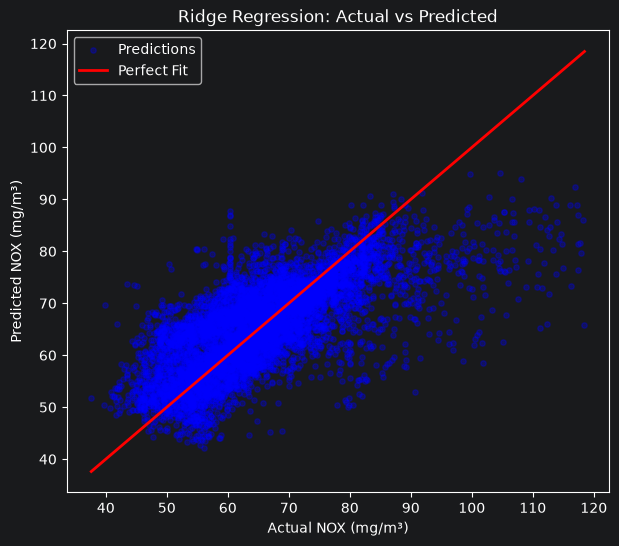

In [20]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_tuned, color='blue', alpha=0.3, s=15, label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Perfect Fit')
plt.xlabel("Actual NOX (mg/m³)")
plt.ylabel("Predicted NOX (mg/m³)")
plt.title("Ridge Regression: Actual vs Predicted")
plt.legend()
plt.show()